Example 
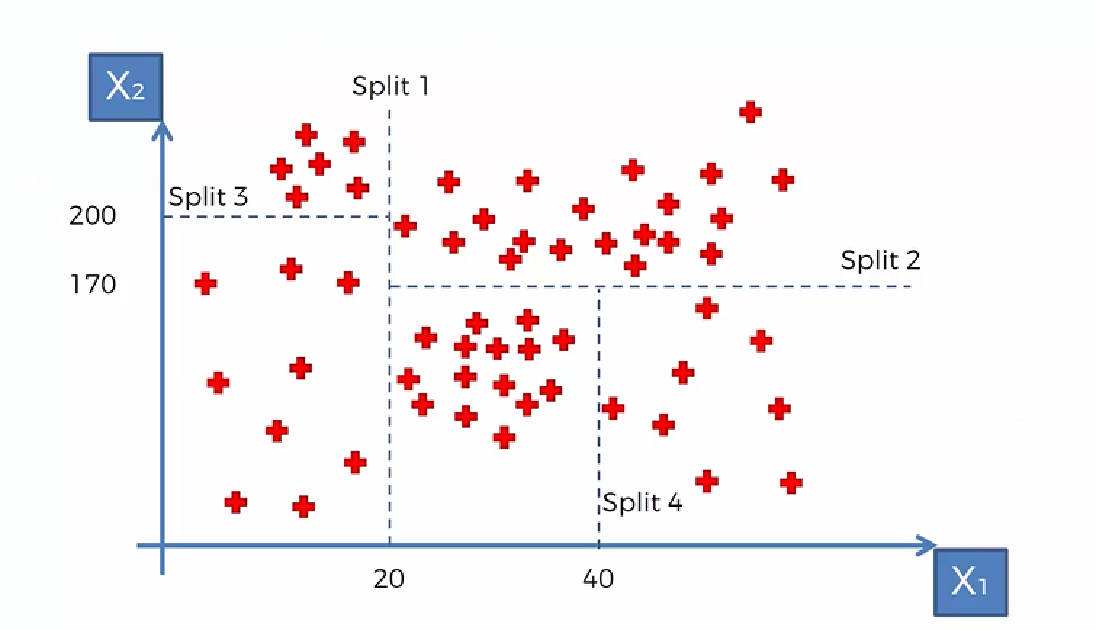

---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

from mlxtend.plotting import plot_decision_regions
from sklearn.tree import plot_tree

In [2]:
df = pd.read_csv('../datasets/Salary_Data.csv')
df.head()

,YearsExperience,Age,Salary
0,1.1,21.0,39343
1,1.3,21.5,46205
2,1.5,21.7,37731
3,2.0,22.0,43525
4,2.2,22.2,39891


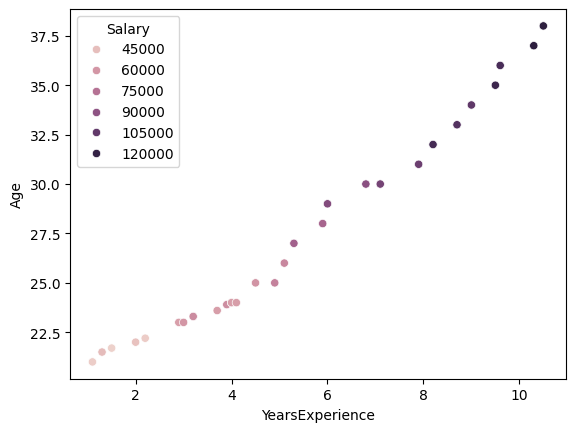

In [3]:
sns.scatterplot(x='YearsExperience', y='Age', data=df, hue='Salary')
plt.show()

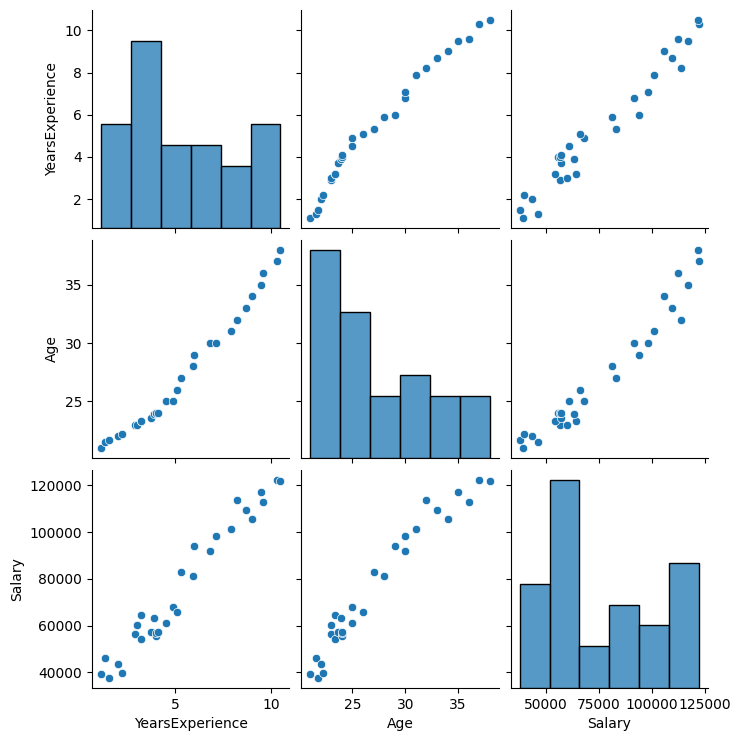

In [4]:
sns.pairplot(data=df)
plt.show()

In [5]:
x = df.iloc[:, :-1]
y = df['Salary']

x.ndim, y.ndim

(2, 1)

In [6]:
ss = StandardScaler()
ss.fit(x)
x = pd.DataFrame(ss.transform(x), columns=x.columns)
x.head()

,YearsExperience,Age
0,-1.510053,-1.225076
1,-1.438373,-1.126544
2,-1.366693,-1.087131
3,-1.187494,-1.028012
4,-1.115814,-0.988600


In [7]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [8]:
dt = DecisionTreeRegressor(max_depth=4)
dt.fit(x_train, y_train)

DecisionTreeRegressor(max_depth=4)

In [9]:
dt.score(x_test, y_test)

0.8048273057963613

In [10]:
dt.score(x_train, y_train)

0.9963768247414004

In [11]:
for i in range(1,20):
    dt_pruning = DecisionTreeRegressor(max_depth=i)
    dt.fit(x_train, y_train)

    print(dt.score(x_test, y_test), "     ", dt.score(x_train, y_train), "     ", i)

0.8188458352893071       0.9963768247414004       1
0.8188458352893071       0.9963768247414004       2
0.8048273057963613       0.9963768247414004       3
0.8048273057963613       0.9963768247414004       4
0.8188458352893071       0.9963768247414004       5
0.8048273057963613       0.9963768247414004       6
0.8048273057963613       0.9963768247414004       7
0.8048273057963613       0.9963768247414004       8
0.8048273057963613       0.9963768247414004       9
0.8188458352893071       0.9963768247414004       10
0.8048273057963613       0.9963768247414004       11
0.8188458352893071       0.9963768247414004       12
0.8188458352893071       0.9963768247414004       13
0.8188458352893071       0.9963768247414004       14
0.8188458352893071       0.9963768247414004       15
0.8048273057963613       0.9963768247414004       16
0.8188458352893071       0.9963768247414004       17
0.8188458352893071       0.9963768247414004       18
0.8048273057963613       0.9963768247414004       19


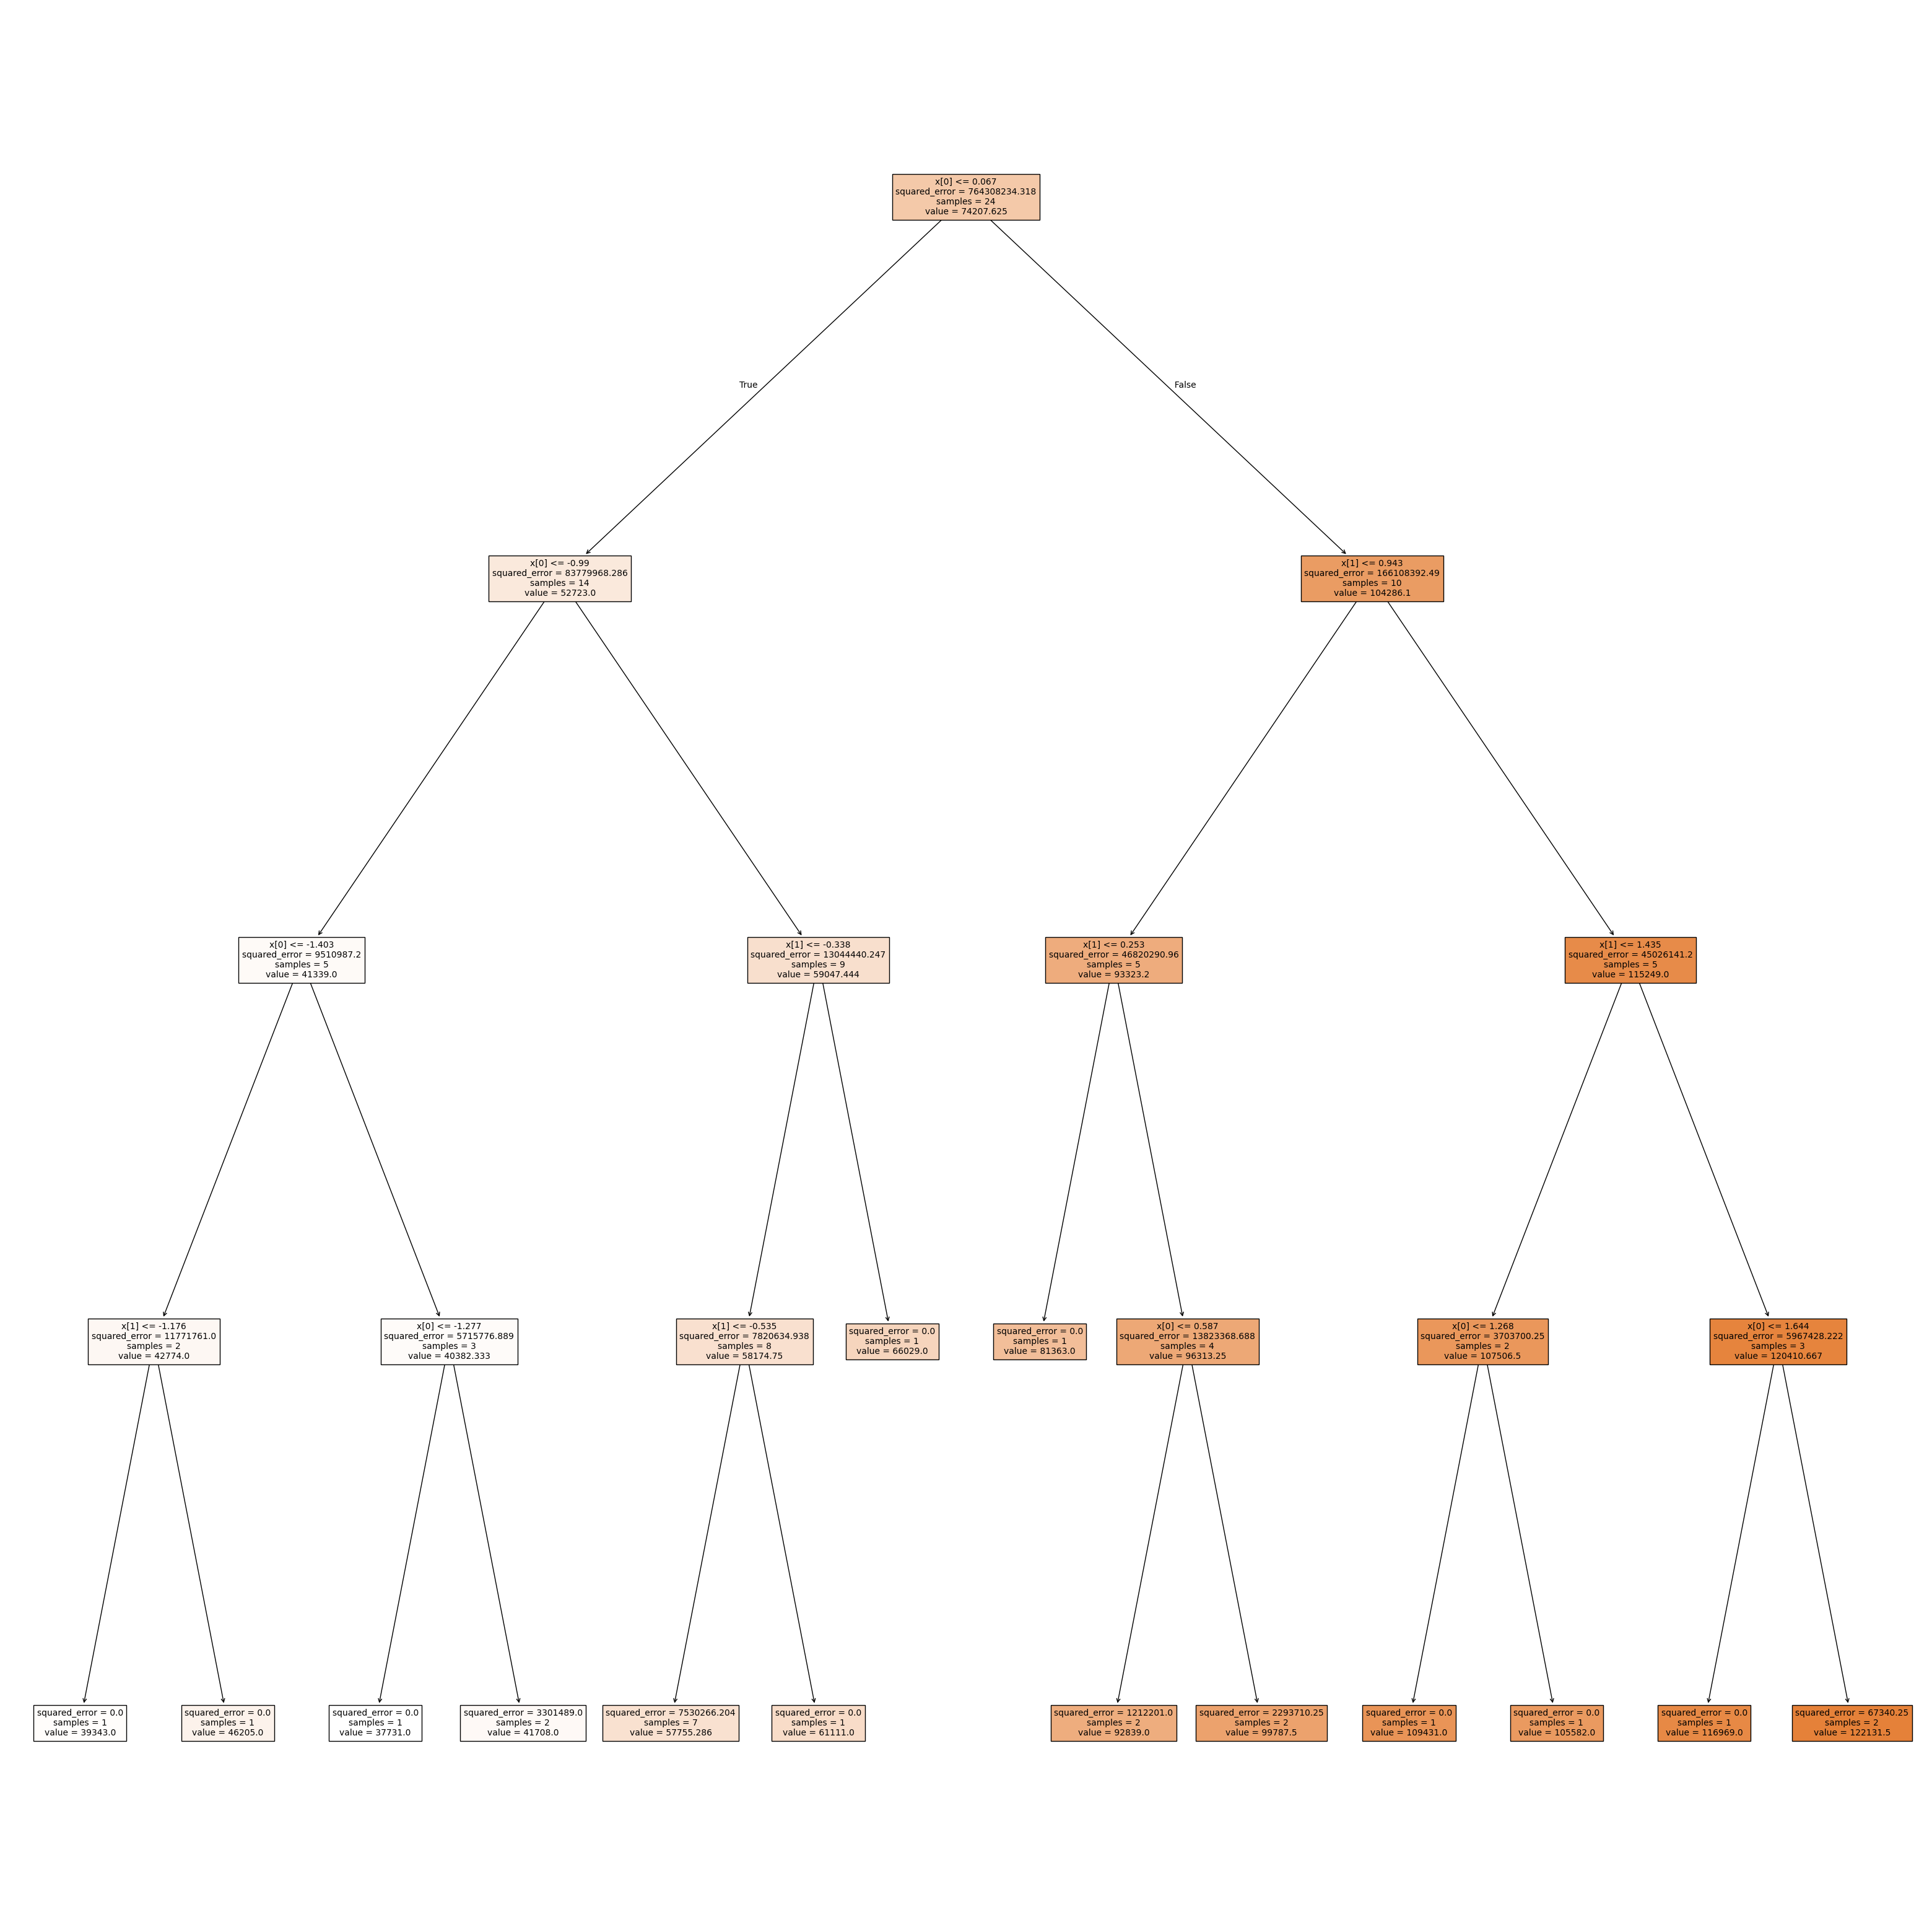

In [12]:
plt.figure(figsize=(40,40))

plot_tree(dt, filled=True)

plt.savefig("./images/regression_tree.jpg")
plt.show()

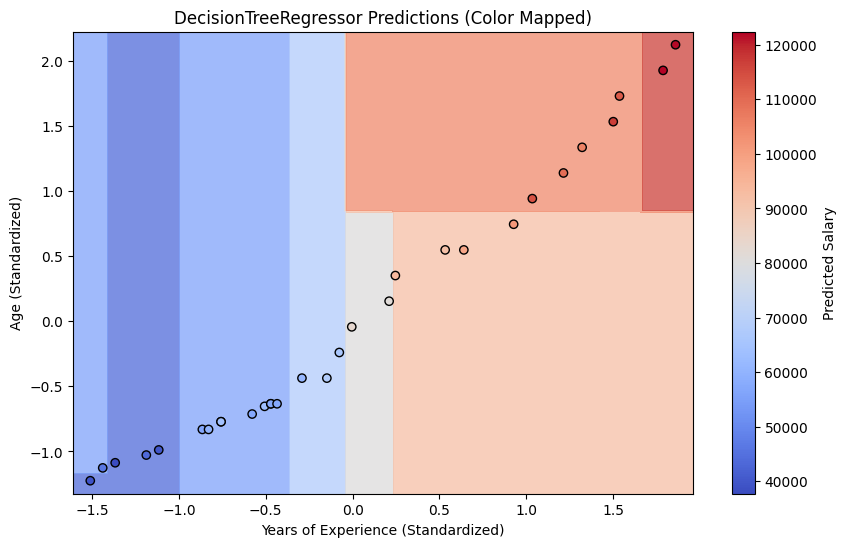

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

X = df[['YearsExperience', 'Age']].values  
y = df['Salary'].values

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Train Decision Tree Regressor
regressor = DecisionTreeRegressor(max_depth=4)
regressor.fit(X, y)

# Create Grid for Plotting Decision Surface
x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
Z = regressor.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot Decision Surface
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.75, cmap=plt.cm.coolwarm)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k", cmap=plt.cm.coolwarm)
plt.xlabel("Years of Experience (Standardized)")
plt.ylabel("Age (Standardized)")
plt.title("DecisionTreeRegressor Predictions (Color Mapped)")
plt.colorbar(label="Predicted Salary")
plt.show()


---